In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# 1. Load the Dataset

uber_df = pd.read_csv('Uber Drives - .csv')

In [5]:
uber_df.head()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit


In [6]:
uber_df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [7]:
uber_df.drop(uber_df.index[-1], inplace = True)

In [8]:
uber_df.index[-1]

1154

In [9]:
uber_df.shape

(1155, 7)

In [10]:
uber_df.info

<bound method DataFrame.info of            START_DATE*         END_DATE* CATEGORY*            START*  \
0       1/1/2016 21:11    1/1/2016 21:17  Business       Fort Pierce   
1        1/2/2016 1:25     1/2/2016 1:37  Business       Fort Pierce   
2       1/2/2016 20:25    1/2/2016 20:38  Business       Fort Pierce   
3       1/5/2016 17:31    1/5/2016 17:45  Business       Fort Pierce   
4       1/6/2016 14:42    1/6/2016 15:49  Business       Fort Pierce   
...                ...               ...       ...               ...   
1150   12/31/2016 1:07   12/31/2016 1:14  Business           Kar?chi   
1151  12/31/2016 13:24  12/31/2016 13:42  Business           Kar?chi   
1152  12/31/2016 15:03  12/31/2016 15:38  Business  Unknown Location   
1153  12/31/2016 21:32  12/31/2016 21:50  Business        Katunayake   
1154  12/31/2016 22:08  12/31/2016 23:51  Business           Gampaha   

                 STOP*  MILES*         PURPOSE*  
0          Fort Pierce     5.1   Meal/Entertain  
1  

In [11]:
# 2. Handle Missing Values

if 'Drop timestamp' in uber_df.columns:
    uber_df['Drop timestamp'] = uber_df['Drop timestamp'].fillna('Not Completed')


In [12]:
# 3. Standardize Datetime Columns
uber_df['START_DATE*'] = pd.to_datetime(uber_df['START_DATE*'], errors='coerce')
uber_df['END_DATE*'] = pd.to_datetime(uber_df['END_DATE*'], errors='coerce')


In [13]:

# 4. Feature Engineering (START_DATE* & END_DATE*)

# Start Date Features
uber_df['Request Hour'] = uber_df['START_DATE*'].dt.hour
uber_df['Request Day'] = uber_df['START_DATE*'].dt.day_name()
uber_df['Request Date'] = uber_df['START_DATE*'].dt.date

# End Date Features
uber_df['End Hour'] = uber_df['END_DATE*'].dt.hour
uber_df['End Day'] = uber_df['END_DATE*'].dt.day_name()
uber_df['End Date'] = uber_df['END_DATE*'].dt.date

# Calculated Duration (in minutes)
uber_df['Duration_mins'] = (uber_df['END_DATE*'] - uber_df['START_DATE*']).dt.total_seconds() / 60

In [14]:
# Categorize hours into time slots
def categorize_time(hour):
    if 4 <= hour < 8:
        return 'Early Morning'
    elif 8 <= hour < 12:
        return 'Morning Peak'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 22:
        return 'Evening Peak'
    else:
        return 'Late Night'

uber_df['Time Slot'] = uber_df['Request Hour'].apply(categorize_time)

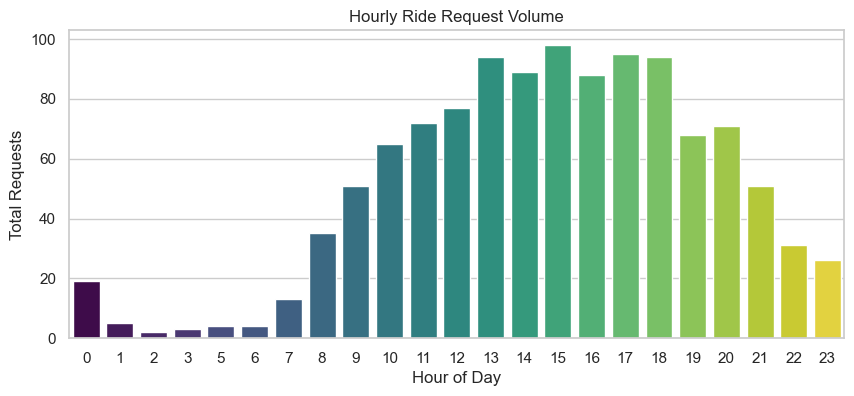

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot 1: Hourly Ride Demand
plt.figure(figsize=(10, 4))
sns.countplot(x='Request Hour', data=uber_df, hue='Request Hour', palette='viridis', legend=False)
plt.title('Hourly Ride Request Volume')
plt.xlabel('Hour of Day')
plt.ylabel('Total Requests')
plt.show()

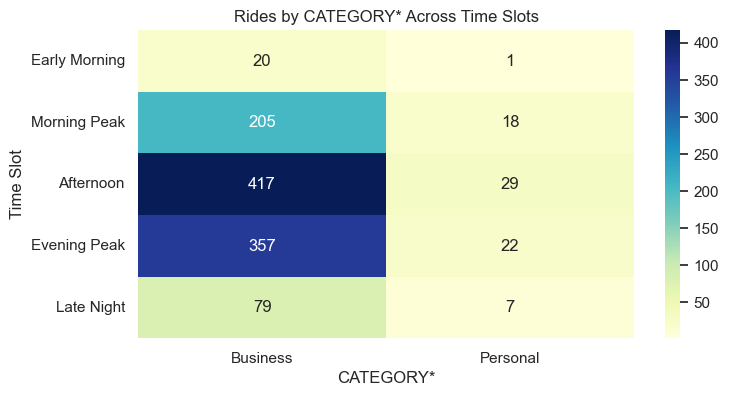

In [16]:
# Plot 2: Demand Across Time Slots by Category
target_col = 'CATEGORY*' if 'CATEGORY*' in uber_df.columns else ('PURPOSE*' if 'PURPOSE*' in uber_df.columns else None)

if target_col:
    plt.figure(figsize=(8, 4))
    slot_order = ['Early Morning', 'Morning Peak', 'Afternoon', 'Evening Peak', 'Late Night']
    pivot_table = pd.crosstab(uber_df['Time Slot'], uber_df[target_col]).reindex(slot_order)
    
    sns.heatmap(pivot_table, annot=True, fmt='g', cmap='YlGnBu')
    plt.title(f'Rides by {target_col} Across Time Slots')
    plt.ylabel('Time Slot')
    plt.show()
else:
    print("Neither 'CATEGORY*' nor 'PURPOSE*' column was found in uber_df.")

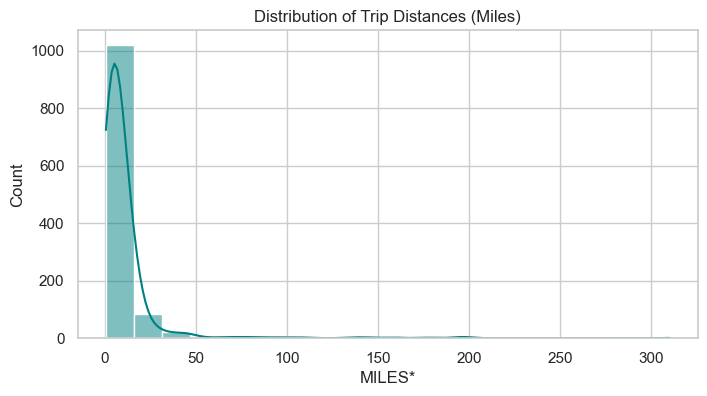

In [17]:
plt.figure(figsize=(8, 4))
sns.histplot(uber_df['MILES*'], bins=20, kde=True, color='teal')
plt.title('Distribution of Trip Distances (Miles)')
plt.show()

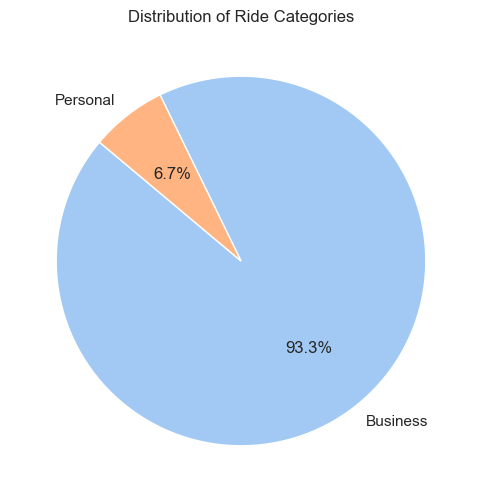

In [18]:

# Pie Chart for Categories
plt.figure(figsize=(6, 6))
category_counts = uber_df['CATEGORY*'].value_counts()

plt.pie(
    category_counts, 
    labels=category_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)
plt.title('Distribution of Ride Categories')
plt.show()

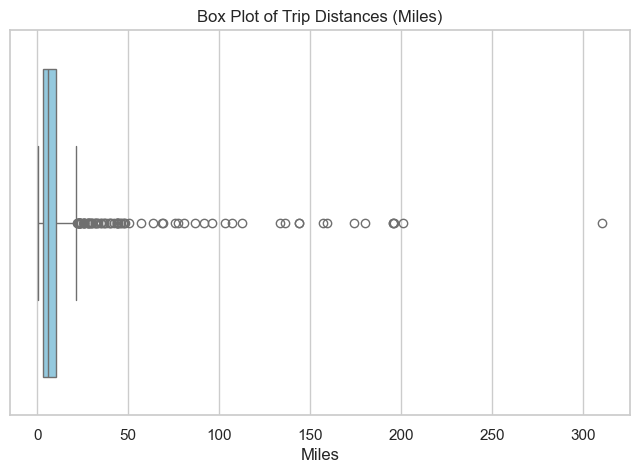

In [19]:
# Box Plot to detect outliers in trip distances
plt.figure(figsize=(8, 5))
sns.boxplot(x=uber_df['MILES*'], color='skyblue')

plt.title('Box Plot of Trip Distances (Miles)')
plt.xlabel('Miles')
plt.show()

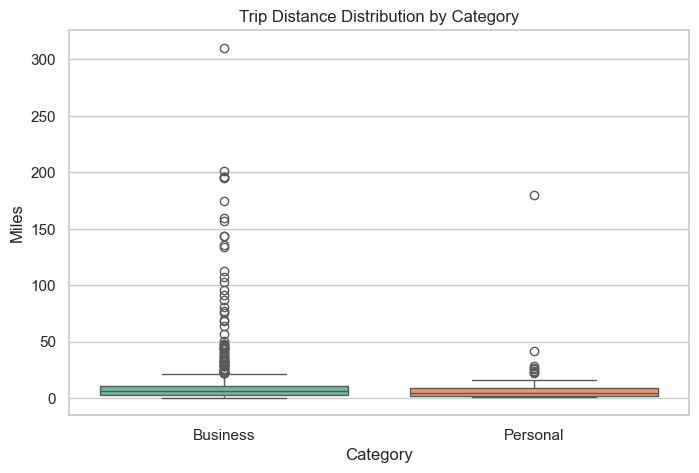

In [20]:
# Compare trip distances across categories
plt.figure(figsize=(8, 5))
sns.boxplot(
    x="CATEGORY*",
    y="MILES*",
    data=uber_df,
    hue="CATEGORY*",
    palette="Set2",
    legend=False,
)

plt.title("Trip Distance Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Miles")
plt.show()

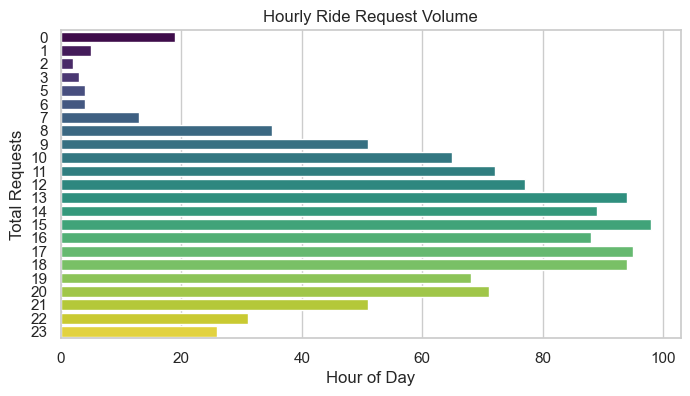

In [21]:
plt.figure(figsize=(8, 4))
sns.countplot(y='Request Hour', data=uber_df, hue='Request Hour', palette='viridis', legend=False)
plt.title('Hourly Ride Request Volume')
plt.xlabel('Hour of Day')
plt.ylabel('Total Requests')
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Aggregate data by hour and day
hourly_df = uber_df.groupby(['Request Date', 'Request Hour', 'Request Day']).size().reset_index(name='Ride_Count')

# Convert categorical day to numeric codes for modeling
hourly_df['Request Day'] = hourly_df['Request Day'].astype('category').cat.codes

# Define Features and Target
X = hourly_df[['Request Hour', 'Request Day']]
y = hourly_df['Ride_Count']

# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate Performance
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Model Performance -> RMSE: {rmse:.2f} | R2 Score: {r2:.2f}")

Model Performance -> RMSE: 0.36 | R2 Score: -0.02
